# DS201 - Lab 2: Mạng neural tích chập


## Cài đặt và import


In [1]:
# Chỉ cần chạy nếu Colab chưa có transformers
# !pip install -q transformers

In [2]:
from pathlib import Path
import random
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


In [3]:
def n_params(model, trainable_only=False):
    params = model.parameters()
    if trainable_only:
        params = (p for p in model.parameters() if p.requires_grad)
    return sum(p.numel() for p in params)

## 1. Import dữ liệu


In [4]:
import os

zip_file = "VinaFood21.zip"
data_dir = "./VinaFood21"
url = "https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR"

if not os.path.exists(data_dir):
    print("Dữ liệu chưa tồn tại. Đang tiến hành tải về...")

    !pip install -q --upgrade gdown
    !gdown {url} -O {zip_file}

    print("Đang giải nén dữ liệu...")
    !unzip -q {zip_file} -d {data_dir}

    if os.path.exists(zip_file):
        os.remove(zip_file)

    print("Hoàn tất chuẩn bị dữ liệu!")
else:
    print("Dữ liệu đã sẵn sàng!")


Dữ liệu chưa tồn tại. Đang tiến hành tải về...
Downloading...
From (original): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR
From (redirected): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR&confirm=t&uuid=8e1ed816-a50d-4579-b79c-56dc6108b676
To: /content/VinaFood21.zip
100% 2.71G/2.71G [00:49<00:00, 54.8MB/s]
Đang giải nén dữ liệu...
Hoàn tất chuẩn bị dữ liệu!


In [5]:
DATA_ROOT = Path("./VinaFood21")
BATCH_SIZE = 32

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

print("DATA_ROOT:", DATA_ROOT.resolve())
print("train:", (DATA_ROOT / "train").is_dir())
print("test :", (DATA_ROOT / "test").is_dir())

DATA_ROOT: /content/VinaFood21
train: False
test : False


In [6]:
def make_loaders(img_size, augment=True, val_ratio=0.15):
    if augment:
        train_tf = transforms.Compose([
            transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    else:
        train_tf = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])

    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])

    train_root = DATA_ROOT / "train"
    val_root = DATA_ROOT / "val"
    test_root = DATA_ROOT / "test"

    if not train_root.is_dir() or not test_root.is_dir():
        raise FileNotFoundError("Cần có VinaFood21/train và VinaFood21/test")

    if val_root.is_dir():
        train_ds = datasets.ImageFolder(train_root, transform=train_tf)
        val_ds = datasets.ImageFolder(val_root, transform=eval_tf)
        classes = train_ds.classes
    else:
        base_ds = datasets.ImageFolder(train_root)
        classes = base_ds.classes

        g = torch.Generator().manual_seed(SEED)
        indices = torch.randperm(len(base_ds), generator=g).tolist()

        n_val = int(len(indices) * val_ratio)
        val_idx = indices[:n_val]
        train_idx = indices[n_val:]

        train_full = datasets.ImageFolder(train_root, transform=train_tf)
        val_full = datasets.ImageFolder(train_root, transform=eval_tf)

        train_ds = Subset(train_full, train_idx)
        val_ds = Subset(val_full, val_idx)

    test_ds = datasets.ImageFolder(test_root, transform=eval_tf)

    train_dl = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=2, pin_memory=torch.cuda.is_available()
    )
    val_dl = DataLoader(
        val_ds, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=2, pin_memory=torch.cuda.is_available()
    )
    test_dl = DataLoader(
        test_ds, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=2, pin_memory=torch.cuda.is_available()
    )

    return train_dl, val_dl, test_dl, classes

In [8]:
import os
from pathlib import Path

nested_dir = Path("./VinaFood21/VinaFood21")
if nested_dir.is_dir() and (nested_dir / "train").is_dir():
    DATA_ROOT = nested_dir
    print("DATA_ROOT:", DATA_ROOT)

# Kiểm tra dữ liệu cho Bài 1
train_dl, val_dl, test_dl, CLASSES = make_loaders(64, augment=True)

xb, yb = next(iter(train_dl))
print("batch:", xb.shape)
print("label:", yb.shape)
print("số lớp:", len(CLASSES))

Đã tự động điều chỉnh DATA_ROOT thành: VinaFood21/VinaFood21
batch: torch.Size([32, 3, 64, 64])
label: torch.Size([32])
số lớp: 21


## 2. Hàm train và đánh giá

In [9]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total, correct, running = 0, 0, 0.0

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)

    return running / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)

        logits = model(xb)
        loss = criterion(logits, yb)
        pred = logits.argmax(1)

        running += loss.item() * yb.size(0)
        correct += (pred == yb).sum().item()
        total += yb.size(0)

        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()

    return running / total, correct / total, y_true, y_pred

In [10]:
def fit(model, train_dl, val_dl, epochs=20, lr=1e-3, trainable_only=False):
    criterion = nn.CrossEntropyLoss()

    params = model.parameters()
    if trainable_only:
        params = filter(lambda p: p.requires_grad, params)

    optimizer = torch.optim.Adam(params, lr=lr)

    history = []

    for ep in range(1, epochs + 1):
        start = time.time()

        tr_loss, tr_acc = train_one_epoch(
            model, train_dl, criterion, optimizer
        )
        va_loss, va_acc, _, _ = evaluate(
            model, val_dl, criterion
        )

        sec = time.time() - start
        history.append((ep, tr_loss, va_loss, tr_acc, va_acc, sec))

        print(
            f"epoch {ep:02d} | "
            f"train {tr_loss:.4f}/{tr_acc:.4f} | "
            f"val {va_loss:.4f}/{va_acc:.4f} | "
            f"{sec:.1f}s"
        )

    return history


def test_metrics(model, test_dl):
    criterion = nn.CrossEntropyLoss()
    _, _, y_true, y_pred = evaluate(model, test_dl, criterion)

    result = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "f1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
    }

    return result, y_true, y_pred


def plot_loss(history, title):
    ep = [x[0] for x in history]
    tr = [x[1] for x in history]
    va = [x[2] for x in history]

    plt.plot(ep, tr, label="train loss")
    plt.plot(ep, va, label="val loss")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title(title)
    plt.legend()
    plt.show()

# Bài 1 - LeNet-5


In [11]:
class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21, pool="avg"):
        super().__init__()

        Pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d

        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = Pool(2, 2)

        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = Pool(2, 2)

        self.n_flat = self._flat_dim(in_ch, img)

        self.f5 = nn.Linear(self.n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)

    def _flat_dim(self, in_ch, img):
        with torch.no_grad():
            x = torch.zeros(1, in_ch, img, img)
            x = self.s2(self.c1(x))
            x = self.s4(self.c3(x))
        return x.flatten(1).shape[1]

    def forward(self, x):
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))

        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))

        return self.out(x)

In [12]:
# Kiểm tra shape và số tham số
lenet = LeNet5(num_classes=21, pool="avg")
print("flatten:", lenet.n_flat)
print("params :", f"{n_params(lenet):,}")
print("output :", lenet(torch.rand(2, 3, 64, 64)).shape)

assert lenet.n_flat == 2704
assert n_params(lenet) == 339_421

flatten: 2704
params : 339,421
output : torch.Size([2, 21])


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 01 | train 2.7991/0.1545 | val 2.5835/0.1946 | 110.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 02 | train 2.5742/0.2166 | val 2.4435/0.2583 | 108.5s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

epoch 18 | train 1.9146/0.4035 | val 2.1427/0.3479 | 110.3s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19 | train 1.9194/0.3968 | val 2.1518/0.3566 | 110.1s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20 | train 1.8831/0.4105 | val 2.1016/0.3599 | 111.8s
{'accuracy': 0.3051481592337624, 'precision_macro': 0.3053511775940001, 'recall_macro': 0.2904922516929992, 'f1_macro': 0.2884982329418848}


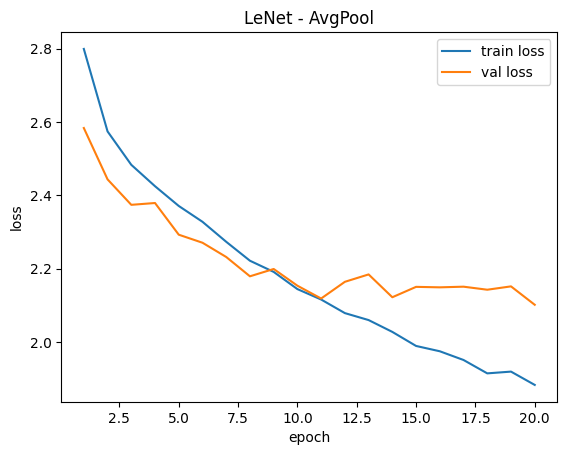

In [13]:
EPOCHS = 20

# AvgPool
set_seed()
train_dl, val_dl, test_dl, CLASSES = make_loaders(64, augment=True)

lenet_avg = LeNet5(
    img=64, num_classes=len(CLASSES), pool="avg"
).to(device)

hist_lenet_avg = fit(
    lenet_avg, train_dl, val_dl,
    epochs=EPOCHS, lr=1e-3
)

result_lenet_avg, y_true, y_pred = test_metrics(
    lenet_avg, test_dl
)

print(result_lenet_avg)
plot_loss(hist_lenet_avg, "LeNet - AvgPool")

In [14]:
# MaxPool
set_seed()
train_dl, val_dl, test_dl, CLASSES = make_loaders(64, augment=True)

lenet_max = LeNet5(
    img=64, num_classes=len(CLASSES), pool="max"
).to(device)

hist_lenet_max = fit(
    lenet_max, train_dl, val_dl,
    epochs=EPOCHS, lr=1e-3
)

result_lenet_max, _, _ = test_metrics(
    lenet_max, test_dl
)

print("AvgPool:", result_lenet_avg)
print("MaxPool:", result_lenet_max)

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 01 | train 2.8303/0.1431 | val 2.6542/0.1919 | 108.1s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 02 | train 2.6079/0.2080 | val 2.5035/0.2331 | 123.5s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

epoch 18 | train 1.7923/0.4377 | val 2.0074/0.3918 | 105.2s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19 | train 1.7855/0.4457 | val 2.0303/0.3878 | 108.6s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20 | train 1.7659/0.4508 | val 2.0494/0.3718 | 106.9s
AvgPool: {'accuracy': 0.3051481592337624, 'precision_macro': 0.3053511775940001, 'recall_macro': 0.2904922516929992, 'f1_macro': 0.2884982329418848}
MaxPool: {'accuracy': 0.31951511523495957, 'precision_macro': 0.332498890752832, 'recall_macro': 0.31096568478231223, 'f1_macro': 0.30504593963218707}


                  precision    recall  f1-score   support

        banh-can     0.1480    0.1535    0.1507       241
        banh-hoi     0.3635    0.3641    0.3638       607
    banh-mi-chao     0.3022    0.2907    0.2963       289
        banh-tet     0.3521    0.1374    0.1976       364
 banh-trang-tron     0.1883    0.1456    0.1642       309
          banh-u     0.2772    0.1591    0.2022       176
        banh-uot     0.2640    0.3125    0.2862       560
       bap-nuong     0.2364    0.0909    0.1313       143
          bo-kho     0.3281    0.3077    0.3176       338
       bo-la-lot     0.4754    0.5699    0.5184       458
       bot-chien     0.1440    0.1304    0.1369       276
           ca-ri     0.1989    0.2105    0.2045       171
    canh-kho-qua     0.4804    0.5931    0.5309       290
   canh-khoai-mo     0.8258    0.6465    0.7252       198
        ga-nuong     0.2558    0.2366    0.2458       372
          goi-ga     0.2562    0.2138    0.2331       290
          ha-

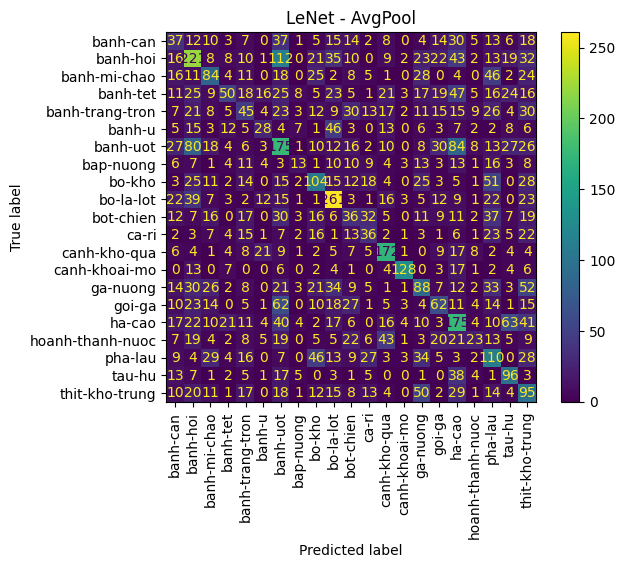

In [15]:
print(classification_report(
    y_true, y_pred,
    target_names=CLASSES,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(
    cm, display_labels=CLASSES
).plot(xticks_rotation=90, values_format="d")

plt.title("LeNet - AvgPool")
plt.show()

# Bài 2 - GoogLeNet rút gọn


In [16]:
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()

        self.b1 = nn.Sequential(
            nn.Conv2d(in_ch, f1, 1),
            nn.ReLU(),
        )

        self.b2 = nn.Sequential(
            nn.Conv2d(in_ch, f3r, 1),
            nn.ReLU(),
            nn.Conv2d(f3r, f3, 3, padding=1),
            nn.ReLU(),
        )

        self.b3 = nn.Sequential(
            nn.Conv2d(in_ch, f5r, 1),
            nn.ReLU(),
            nn.Conv2d(f5r, f5, 5, padding=2),
            nn.ReLU(),
        )

        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_ch, fp, 1),
            nn.ReLU(),
        )

    def forward(self, x):
        return torch.cat([
            self.b1(x),
            self.b2(x),
            self.b3(x),
            self.b4(x),
        ], dim=1)

In [17]:
class GoogLeNetSmall(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )

        self.inc1 = InceptionBlock(
            32, 16, 16, 24, 4, 8, 8
        )   # 56 channels

        self.pool1 = nn.MaxPool2d(2, 2)

        self.inc2 = InceptionBlock(
            56, 32, 32, 48, 8, 16, 16
        )   # 112 channels

        self.pool2 = nn.MaxPool2d(2, 2)

        self.inc3 = InceptionBlock(
            112, 48, 32, 64, 8, 16, 16
        )   # 144 channels

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(144, num_classes)

    def forward(self, x):
        x = self.stem(x)

        x = self.inc1(x)
        x = self.pool1(x)

        x = self.inc2(x)
        x = self.pool2(x)

        x = self.inc3(x)

        x = self.pool(x).flatten(1)
        return self.fc(x)

In [18]:
# Kiểm tra channel output
model = GoogLeNetSmall(num_classes=21)

x = torch.rand(1, 3, 64, 64)
x = model.stem(x)

x = model.inc1(x)
print("inc1:", x.shape)

x = model.pool1(x)
x = model.inc2(x)
print("inc2:", x.shape)

x = model.pool2(x)
x = model.inc3(x)
print("inc3:", x.shape)

print("params:", f"{n_params(model):,}")
print("output:", model(torch.rand(2, 3, 64, 64)).shape)

inc1: torch.Size([1, 56, 32, 32])
inc2: torch.Size([1, 112, 16, 16])
inc3: torch.Size([1, 144, 8, 8])
params: 65,249
output: torch.Size([2, 21])


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 01 | train 2.8866/0.1211 | val 2.7790/0.1414 | 102.8s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 02 | train 2.6499/0.1866 | val 2.4723/0.2297 | 101.8s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

epoch 18 | train 1.7710/0.4512 | val 1.7285/0.4714 | 106.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19 | train 1.7495/0.4536 | val 1.7490/0.4522 | 108.3s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20 | train 1.7263/0.4609 | val 1.8306/0.4548 | 110.1s
{'accuracy': 0.3762346602813529, 'precision_macro': 0.4060312162760387, 'recall_macro': 0.34481049017296883, 'f1_macro': 0.34629426789462986}


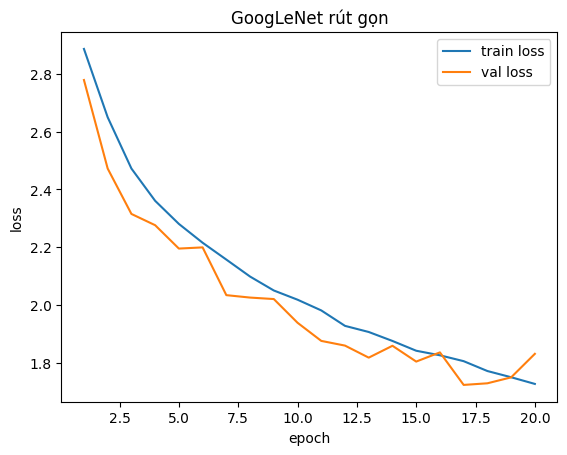

In [19]:
set_seed()
train_dl, val_dl, test_dl, CLASSES = make_loaders(64, augment=True)

googlenet = GoogLeNetSmall(
    num_classes=len(CLASSES)
).to(device)

hist_googlenet = fit(
    googlenet, train_dl, val_dl,
    epochs=EPOCHS, lr=1e-3
)

result_googlenet, y_true, y_pred = test_metrics(
    googlenet, test_dl
)

print(result_googlenet)
plot_loss(hist_googlenet, "GoogLeNet rút gọn")

In [20]:
print(classification_report(
    y_true, y_pred,
    target_names=CLASSES,
    digits=4,
    zero_division=0
))

                  precision    recall  f1-score   support

        banh-can     0.3187    0.2116    0.2544       241
        banh-hoi     0.3175    0.7397    0.4443       607
    banh-mi-chao     0.6277    0.2042    0.3081       289
        banh-tet     0.4302    0.5165    0.4694       364
 banh-trang-tron     0.2850    0.1909    0.2287       309
          banh-u     0.2542    0.2557    0.2550       176
        banh-uot     0.2714    0.3000    0.2850       560
       bap-nuong     0.2833    0.1189    0.1675       143
          bo-kho     0.4850    0.2870    0.3606       338
       bo-la-lot     0.5148    0.7205    0.6005       458
       bot-chien     0.2422    0.1957    0.2164       276
           ca-ri     0.2733    0.2749    0.2741       171
    canh-kho-qua     0.5248    0.5483    0.5363       290
   canh-khoai-mo     0.7889    0.7172    0.7513       198
        ga-nuong     0.4766    0.1371    0.2129       372
          goi-ga     0.3967    0.2517    0.3080       290
          ha-

# Bài 3* - ResNet-18


In [21]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_ch, out_ch, 3,
            stride=stride, padding=1,
            bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_ch)

        self.conv2 = nn.Conv2d(
            out_ch, out_ch, 3,
            stride=1, padding=1,
            bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_ch)

        self.shortcut = nn.Identity()

        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_ch, out_ch, 1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_ch),
            )

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + self.shortcut(x)

        return torch.relu(out)

In [22]:
class ResNet18(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(
                3, 64, 7,
                stride=2, padding=3,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(3, stride=2, padding=1),
        )

        self.layer1 = self._stage(64, 64, 1)
        self.layer2 = self._stage(64, 128, 2)
        self.layer3 = self._stage(128, 256, 2)
        self.layer4 = self._stage(256, 512, 2)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    @staticmethod
    def _stage(in_ch, out_ch, stride):
        return nn.Sequential(
            BasicBlock(in_ch, out_ch, stride),
            BasicBlock(out_ch, out_ch, 1),
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.pool(x).flatten(1)
        return self.fc(x)

In [23]:
resnet18 = ResNet18(num_classes=21)

print("params:", f"{n_params(resnet18):,}")
print("output:", resnet18(torch.rand(2, 3, 96, 96)).shape)

assert n_params(resnet18) == 11_187_285

params: 11,187,285
output: torch.Size([2, 21])


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 01 | train 2.6378/0.2019 | val 2.5503/0.2205 | 107.5s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 02 | train 2.3524/0.2727 | val 2.3340/0.2882 | 107.1s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

epoch 18 | train 0.0846/0.9725 | val 2.7484/0.4987 | 107.4s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19 | train 0.0624/0.9807 | val 3.0292/0.4861 | 109.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20 | train 0.0792/0.9766 | val 3.2860/0.4655 | 106.2s
{'accuracy': 0.39314576474109547, 'precision_macro': 0.4256723086094468, 'recall_macro': 0.3769585083769099, 'f1_macro': 0.37917586590037916}


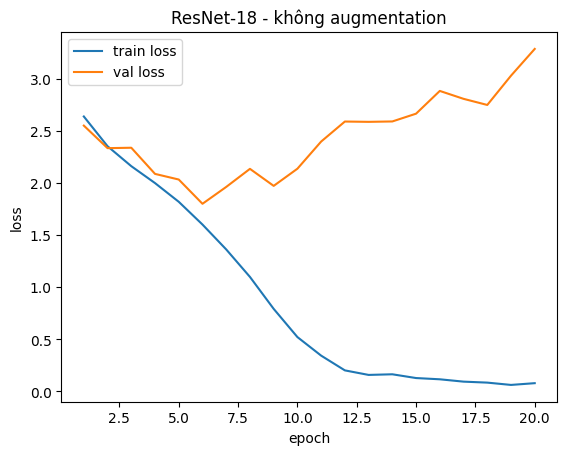

In [24]:
# Lần 1: không augmentation
set_seed()
train_dl_plain, val_dl_plain, test_dl_96, CLASSES = make_loaders(
    96, augment=False
)

resnet_plain = ResNet18(
    num_classes=len(CLASSES)
).to(device)

hist_resnet_plain = fit(
    resnet_plain,
    train_dl_plain,
    val_dl_plain,
    epochs=EPOCHS,
    lr=1e-3
)

result_resnet_plain, _, _ = test_metrics(
    resnet_plain, test_dl_96
)

print(result_resnet_plain)
plot_loss(hist_resnet_plain, "ResNet-18 - không augmentation")

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 01 | train 2.7176/0.1859 | val 2.6100/0.1985 | 117.7s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 02 | train 2.4739/0.2430 | val 2.3943/0.2610 | 115.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

epoch 18 | train 1.2103/0.6075 | val 1.4165/0.5657 | 114.8s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19 | train 1.1470/0.6279 | val 1.4676/0.5491 | 114.2s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20 | train 1.0909/0.6489 | val 1.7256/0.5159 | 116.0s
Không augmentation: {'accuracy': 0.39314576474109547, 'precision_macro': 0.4256723086094468, 'recall_macro': 0.3769585083769099, 'f1_macro': 0.37917586590037916}
Có augmentation   : {'accuracy': 0.459892247829991, 'precision_macro': 0.46308721612239256, 'recall_macro': 0.4537829628864144, 'f1_macro': 0.42930488450734583}


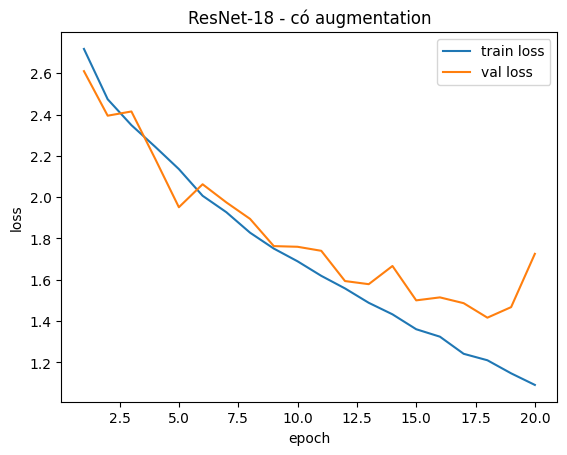

In [25]:
# Lần 2: có augmentation
set_seed()
train_dl_aug, val_dl_aug, test_dl_96, CLASSES = make_loaders(
    96, augment=True
)

resnet_aug = ResNet18(
    num_classes=len(CLASSES)
).to(device)

hist_resnet_aug = fit(
    resnet_aug,
    train_dl_aug,
    val_dl_aug,
    epochs=EPOCHS,
    lr=1e-3
)

result_resnet_aug, y_true, y_pred = test_metrics(
    resnet_aug, test_dl_96
)

print("Không augmentation:", result_resnet_plain)
print("Có augmentation   :", result_resnet_aug)

plot_loss(hist_resnet_aug, "ResNet-18 - có augmentation")